#              **Modélisation du risque d’assurance par simulation Monte-Carlo**
## -Introduction

### L'objectif du projet:

Ce projet vise à modéliser les pertes annuelles d'un portefeuille fictif d'assurance à l'aide de Python.

L'approche repose sur un modèle fréquence-sévérité qui distingue deux composantes du risque :

- La fréquence des sinistres :le nombre de sinistres survenant pendant une année.
-  La sévérité des sinistres:le coût individuel de chaque sinistre.

À partir de ces deux composantes, nous simulons les pertes totales du portefeuille, puis utilisons une méthode de Monte-Carlo pour étudier la variabilité des pertes annuelles, estimer les probabilités de dépassement de différents seuils et analyser le quantile à 95 %.

### Hypothèses initiales
Le modèle repose sur les hypothèses suivantes :
- Un portefeuille fictif de 1 000 assurés.
- Un nombre annuel de sinistres par assuré suivant une **loi de Poisson**.
- Un coût individuel des sinistres suivant une **loi exponentielle**.
- Des assurés présentant une fréquence de sinistres identique.
- Des nombres de sinistres indépendants entre assurés et des coûts individuels indépendants de la fréquence et entre eux.

Precision; les paramètres numériques sont hypothétiques et ne proviennent pas de données historiques réelles. Ils ont été choisis pour illustrer les principes de la modélisation actuarielle. Leurs limites seront discutées dans l'analyse méthodologique du projet.

## 2. Simulation de la fréquence des sinistres

### Objectif

Cette section consiste à simuler le nombre de sinistres survenant pendant une année pour chacun des 1 000 assurés du portefeuille.

### Modélisation par la loi de Poisson

Nous supposons que le nombre annuel de sinistres par assuré suit une loi de Poisson de paramètre λ = 0,2.

La loi de Poisson est une distribution de probabilité discrète permettant de modéliser le nombre d'événements survenant pendant une période donnée.

Dans notre modèle, λ = 0,2 signifie qu'un assuré présente en moyenne 0,2 sinistre par année. Cela ne signifie pas que chaque assuré subit exactement 0,2 sinistre : certains n'en auront aucun, tandis que d'autres pourront en avoir un ou plusieurs.

Pour un portefeuille de 1 000 assurés, le nombre total de sinistres attendu est donc :

E[N] = 1 000 × 0,2 = 200 sinistres par année.

### Simulation avec Python

Nous utilisons la bibliothèque NumPy pour générer aléatoirement le nombre annuel de sinistres de chaque assuré selon cette distribution.

La fonction `rng.poisson()` permet de réaliser cette simulation, tandis que le paramètre `size=nombre_assures` indique que nous souhaitons obtenir une valeur pour chacun des 1 000 assurés.

La graine aléatoire fixée à 42 permet de reproduire les mêmes résultats lors d'une nouvelle exécution du notebook dans les mêmes conditions.

In [ ]:

import numpy as np

# Paramètres de notre portefeuille fictif
nombre_assures = 1000
lambda_sinistres = 0.2

# Générateur aléatoire reproductible
rng = np.random.default_rng(42)

# Simuler le nombre de sinistres de chaque assuré
sinistres = rng.poisson(
    lam=lambda_sinistres,
    size=nombre_assures
)

print(sinistres[:20])


[0 0 1 0 1 0 0 0 0 1 1 0 0 0 1 0 0 2 0 0]


### Interprétation des résultats

La simulation a généré un total de 205 sinistres pour les 1 000 assurés, soit une fréquence observée de 0,205 sinistre par assuré.

Cette fréquence est proche de la fréquence théorique de 0,2 utilisée dans le modèle.

Par ailleurs, 811 assurés n'ont subi aucun sinistre pendant l'année simulée.

La différence entre les 200 sinistres attendus et les 205 sinistres observés s'explique par le caractère aléatoire de la simulation. Une nouvelle simulation pourrait produire un nombre différent de sinistres.

In [ ]:

# Nombre total de sinistres
total_sinistres = sinistres.sum()

# Nombre moyen de sinistres par assuré
moyenne = sinistres.mean()

# Nombre d'assurés sans sinistre
sans_sinistre = np.sum(sinistres == 0)

print("Total des sinistres :", total_sinistres)
print("Moyenne par assuré :", moyenne)
print("Assurés sans sinistre :", sans_sinistre)


Total des sinistres : 205
Moyenne par assuré : 0.205
Assurés sans sinistre : 811


## 3. Simulation du coût des sinistres

Après avoir simulé le nombre de sinistres, nous modélisons leur coût individuel à l'aide d'une loi exponentielle de moyenne théorique de 1 500 $.

Cette distribution permet de générer des coûts variables, avec davantage de sinistres peu coûteux et moins de sinistres très coûteux. Le montant de 1 500 $ est une hypothèse de modélisation et non un coût fixe par sinistre.

La fonction `rng.exponential()` génère un coût pour chacun des sinistres simulés.

In [ ]:

# Coût moyen théorique d'un sinistre
cout_moyen = 1500

# Générer un coût aléatoire pour chacun des 205 sinistres
couts_sinistres = rng.exponential(
    scale=cout_moyen,
    size=total_sinistres
)

# Afficher les 10 premiers coûts
print("Les 10 premiers coûts :")
print(couts_sinistres[:10])

# Calculer le coût moyen simulé
print("Coût moyen simulé :", couts_sinistres.mean())

# Calculer les pertes totales
perte_totale = couts_sinistres.sum()

print("Perte totale :", perte_totale)


Les 10 premiers coûts :
[ 283.81107625  671.40394454  638.03584073  294.71375478 1661.94113995
  833.27996033 3255.57506118  654.24405982 1118.69722789  820.85490625]
Coût moyen simulé : 1463.8760622344093
Perte totale : 300094.5927580539


### Résultats

La simulation a généré 205 sinistres, avec un coût moyen observé de 1 463,8  et une perte totale de 300 094,59 $.



### Visualisation des coûts des sinistres

Cet histogramme permet de visualiser la répartition des coûts individuels des 205 sinistres simulés.

La ligne rouge représente le coût moyen observé, soit environ 1 463,88 $.

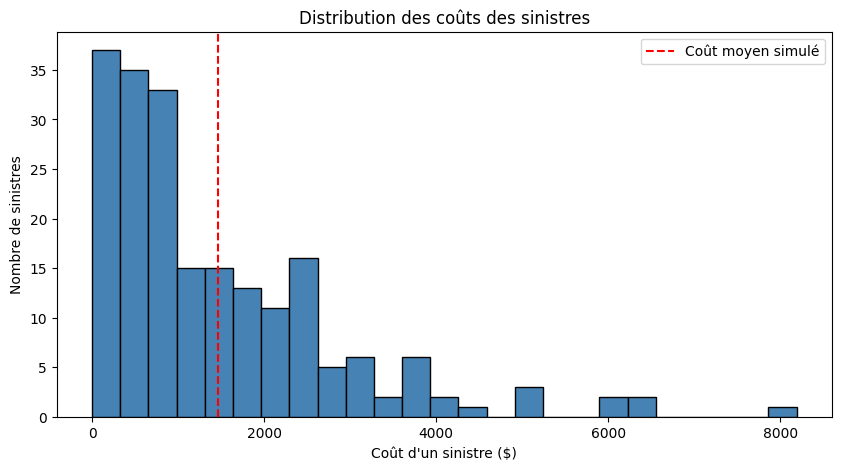

In [ ]:

import matplotlib.pyplot as plt

# Créer un histogramme des coûts simulés
plt.figure(figsize=(10, 5))

plt.hist(
    couts_sinistres,
    bins=25,
    color="steelblue",
    edgecolor="black"
)

# Ajouter les titres
plt.title("Distribution des coûts des sinistres")
plt.xlabel("Coût d'un sinistre ($)")
plt.ylabel("Nombre de sinistres")

# Ajouter une ligne pour le coût moyen simulé
plt.axvline(
    couts_sinistres.mean(),
    color="red",
    linestyle="--",
    label="Coût moyen simulé"
)

plt.legend()
plt.show()



L'histogramme montre une distribution asymétrique: les couts relativement faibles sont plus frequents que les coûts élevés.


## 4. Simulation Monte-Carlo des pertes annuelles

### Objectif

Une seule simulation ne suffit pas pour comprendre la variabilité des pertes d'un portefeuille d'assurance.

Nous utilisons donc la méthode de Monte-Carlo pour simuler 10 000 années indépendantes. Pour chaque année, nous générons un nombre aléatoire de sinistres selon une loi de Poisson, puis leurs coûts selon une loi exponentielle.

Cette approche permet d'étudier la distribution des pertes annuelles et d'estimer la probabilité que celles-ci dépassent certains seuils.

In [ ]:

# Nombre d'années à simuler
nombre_simulations = 10000

# Liste pour stocker les pertes de chaque année
pertes_annuelles = []

# Simuler 10 000 années
for i in range(nombre_simulations):

    # Nombre total de sinistres pendant cette année
    nb_sinistres = rng.poisson(
        lam=nombre_assures * lambda_sinistres
    )

    # Coûts des sinistres de cette année
    couts = rng.exponential(
        scale=cout_moyen,
        size=nb_sinistres
    )

    # Perte totale de cette année
    perte = couts.sum()

    # Enregistrer la perte
    pertes_annuelles.append(perte)

# Convertir la liste en tableau NumPy
pertes_annuelles = np.array(pertes_annuelles)

print("Nombre d'années simulées :", len(pertes_annuelles))
print("Pertes des 5 premières années :")
print(pertes_annuelles[:5])


Nombre d'années simulées : 10000
Pertes des 5 premières années :
[308478.19387037 327450.98042874 284412.96335555 274223.31566168
 311349.01527189]


In [ ]:

# Perte annuelle moyenne
perte_moyenne = pertes_annuelles.mean()

# Probabilité de dépasser certains montants
proba_300k = np.mean(pertes_annuelles > 300000)
proba_400k = np.mean(pertes_annuelles > 400000)

print(f"Perte annuelle moyenne : {perte_moyenne:,.2f} $")
print(f"Probabilité de dépasser 300 000 $ : {proba_300k:.2%}")
print(f"Probabilité de dépasser 400 000 $ : {proba_400k:.2%}")


Perte annuelle moyenne : 299,929.74 $
Probabilité de dépasser 300 000 $ : 48.74%
Probabilité de dépasser 400 000 $ : 0.10%


### Résultats de la simulation Monte-Carlo

La perte annuelle moyenne obtenue sur les 10 000 simulations est d'environ 299 929,74 , ce qui est proche de la perte théorique attendue de 300 000 $.

La probabilité estimée que les pertes annuelles dépassent 300 000 est de 48,74 %, tandis que celle de dépasser 400 000 $ est de 0,10 %.

Ces résultats montrent que les pertes peuvent varier d'une année à l'autre, même lorsque les paramètres du modèle restent identiques.

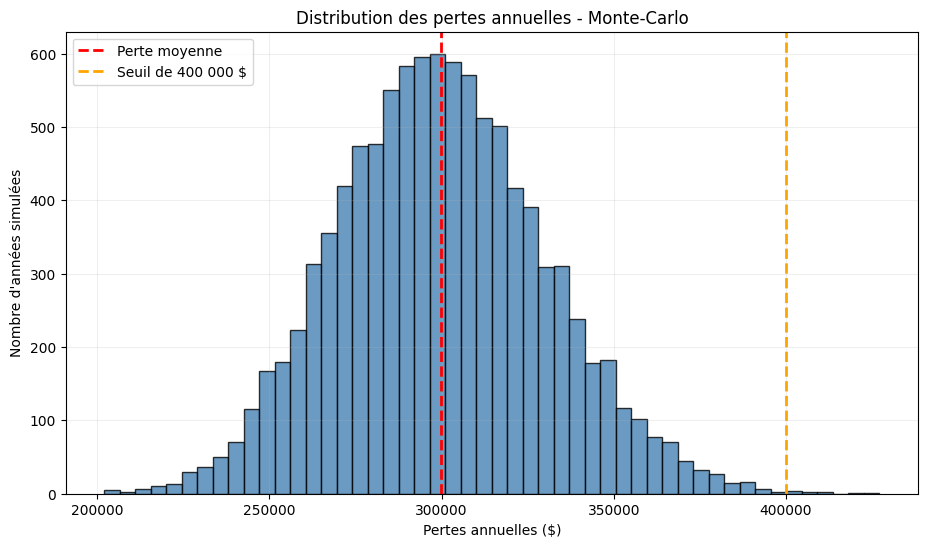

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# Histogramme des 10 000 pertes annuelles
plt.hist(
    pertes_annuelles,
    bins=50,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

# Perte moyenne
plt.axvline(
    perte_moyenne,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perte moyenne"
)

# Seuil de 400 000 $
plt.axvline(
    400000,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Seuil de 400 000 $"
)

plt.title("Distribution des pertes annuelles - Monte-Carlo")
plt.xlabel("Pertes annuelles ($)")
plt.ylabel("Nombre d'années simulées")

plt.legend()
plt.grid(alpha=0.2)
plt.show()


### Analyse du quantile à 95 %
Le quantile à 95 %, également appelé Value at Risk (VaR) à 95 %, est estimé à 351 618,80 $. Dans le modèle simulé, ce montant constitue un seuil de perte annuelle dépassé avec une probabilité d'environ 5 %. Il ne représente toutefois pas la perte maximale possible.

In [ ]:

# Quantile à 95 % des pertes annuelles
seuil_95 = np.percentile(pertes_annuelles, 95)

print(f"Quantile à 95 % : {seuil_95:,.2f} $")


Quantile à 95 % : 351,618.80 $


## Conclusion et limites du modèle

Ce projet vise à modéliser les pertes annuelles d'un portefeuille fictif de 1 000 assurés à l'aide de Python.

La fréquence des sinistres a été modélisée par une loi de Poisson de paramètre λ = 0,2 par assuré et par année, tandis que leurs coûts ont été simulés avec une loi exponentielle de moyenne 1 500 $.

Une simulation Monte-Carlo de 10 000 années a permis d'obtenir les résultats suivants :

- **Perte annuelle moyenne simulée :** 299 929,74
- **Probabilite estimée de dépasser 300 000:** 48,74 %
- **Probabilité estimée de dépasser 400 000:** 0,10 %
- **Quantile à 95 % des pertes annuelles :** 351 618,80 $

Ces résultats montrent que, même lorsque la perte moyenne est connue, les pertes réelles peuvent varier considérablement d'une année à l'autre.

### Limites

Ce modèle repose sur des hypothèses simplificatrices : les paramètres sont fictifs, les assurés ont la même fréquence de sinistres et les coûts sont supposés indépendants et identiquement distribués.

Les résultats ne constituent donc pas une prévision des pertes d'une compagnie réelle.

Une amélioration possible serait d'estimer les paramètres à partir de données historiques d'assurance et de comparer plusieurs distributions de coûts.